In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Parametric Rainfall Insurance Project")
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Setup completed successfully!")

Parametric Rainfall Insurance Project
NumPy version: 2.1.3
Pandas version: 2.3.3
Setup completed successfully!


In [2]:
import requests


url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": 23.0225,
    "longitude": 72.5714,
    "start_date": "2015-01-01",
    "end_date": "2024-12-31",
    "daily": "precipitation_sum",
    "timezone": "Asia/Kolkata"
}

response = requests.get(url, params=params, timeout=60)
response.raise_for_status()

data = response.json()

rainfall_df = pd.DataFrame({
    "date": data["daily"]["time"],
    "rainfall_mm": data["daily"]["precipitation_sum"]
})

rainfall_df["date"] = pd.to_datetime(rainfall_df["date"])

print(rainfall_df.head())
print("\nDataset shape:", rainfall_df.shape)
print("\nMissing values:\n", rainfall_df.isnull().sum())

        date  rainfall_mm
0 2015-01-01          0.0
1 2015-01-02          0.0
2 2015-01-03          0.0
3 2015-01-04          0.0
4 2015-01-05          0.0

Dataset shape: (3653, 2)

Missing values:
 date           0
rainfall_mm    0
dtype: int64


Rainfall Statistics
count    3653.000000
mean        2.830523
std        12.424727
min         0.000000
25%         0.000000
50%         0.000000
75%         0.300000
max       339.900000
Name: rainfall_mm, dtype: float64

Dry days: 2530
Rainy days: 1123
Dry days (%): 69.26


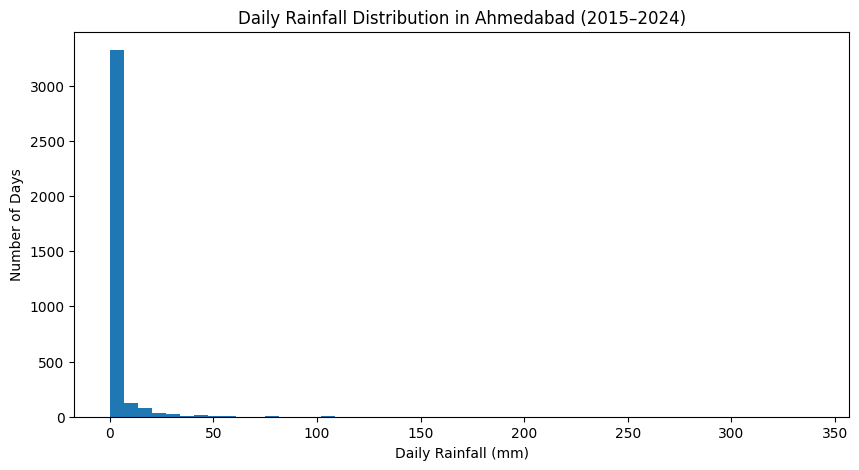

In [3]:
# Basic rainfall statistics
print("Rainfall Statistics")
print(rainfall_df["rainfall_mm"].describe())

# Count dry and rainy days
dry_days = (rainfall_df["rainfall_mm"] == 0).sum()
rainy_days = (rainfall_df["rainfall_mm"] > 0).sum()

print("\nDry days:", dry_days)
print("Rainy days:", rainy_days)
print("Dry days (%):", round(dry_days / len(rainfall_df) * 100, 2))

# Visualize rainfall distribution
plt.figure(figsize=(10, 5))
plt.hist(rainfall_df["rainfall_mm"], bins=50)
plt.xlabel("Daily Rainfall (mm)")
plt.ylabel("Number of Days")
plt.title("Daily Rainfall Distribution in Ahmedabad (2015–2024)")
plt.show()

   year  annual_rainfall_mm  rainy_days  max_daily_rainfall_mm
0  2015               610.6          85                  143.8
1  2016               712.2          95                  107.5
2  2017              1578.0         105                  339.9
3  2018               751.1         103                   83.8
4  2019              1237.1         131                  120.8
5  2020              1015.1         123                  101.4
6  2021              1050.1         126                  106.5
7  2022              1014.7         112                  168.3
8  2023              1035.9         125                  111.4
9  2024              1335.1         118                  128.3


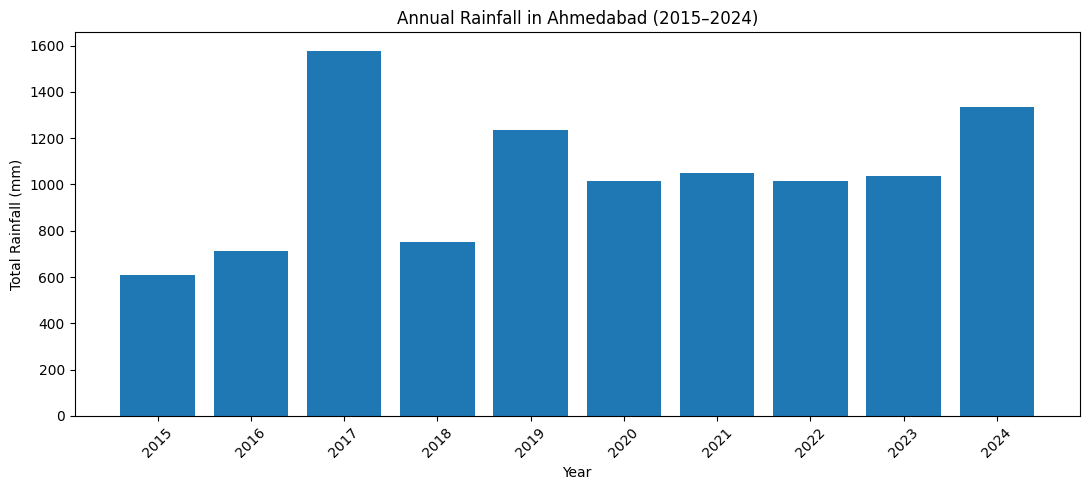

In [4]:
# Extract year
rainfall_df["year"] = rainfall_df["date"].dt.year

# Calculate annual rainfall metrics
annual_rainfall = rainfall_df.groupby("year").agg(
    annual_rainfall_mm=("rainfall_mm", "sum"),
    rainy_days=("rainfall_mm", lambda x: (x > 0).sum()),
    max_daily_rainfall_mm=("rainfall_mm", "max")
).reset_index()

print(annual_rainfall.round(2))

# Plot annual rainfall
plt.figure(figsize=(11, 5))
plt.bar(
    annual_rainfall["year"],
    annual_rainfall["annual_rainfall_mm"]
)
plt.xlabel("Year")
plt.ylabel("Total Rainfall (mm)")
plt.title("Annual Rainfall in Ahmedabad (2015–2024)")
plt.xticks(annual_rainfall["year"], rotation=45)
plt.tight_layout()
plt.show()

   year  monsoon_rainfall_mm  rainy_days
0  2015                564.9          73
1  2016                594.0          80
2  2017               1561.5          99
3  2018                750.0          97
4  2019               1177.4         105
5  2020                984.8         109
6  2021                935.5         103
7  2022                949.5          99
8  2023                935.4         100
9  2024               1260.4          98

Monsoon rainfall statistics:
count      10.000000
mean      971.340000
std       304.432062
min       564.900000
25%       796.350000
50%       942.500000
75%      1129.250000
max      1561.500000
Name: monsoon_rainfall_mm, dtype: float64


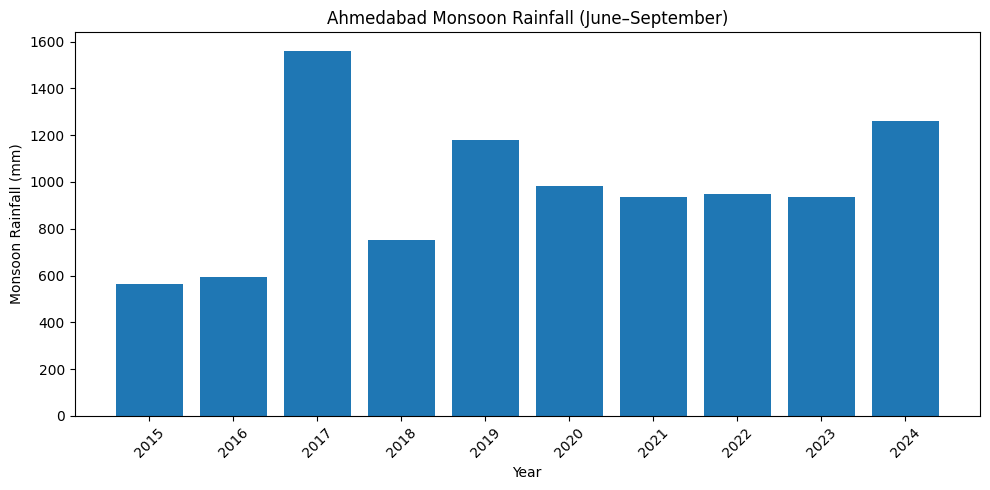

In [5]:
# Filter June to September
monsoon_df = rainfall_df[
    rainfall_df["date"].dt.month.isin([6, 7, 8, 9])
].copy()

# Aggregate rainfall for each monsoon season
monsoon_rainfall = monsoon_df.groupby(
    monsoon_df["date"].dt.year
).agg(
    monsoon_rainfall_mm=("rainfall_mm", "sum"),
    rainy_days=("rainfall_mm", lambda x: (x > 0).sum())
).reset_index()

monsoon_rainfall.rename(
    columns={"date": "year"},
    inplace=True
)

print(monsoon_rainfall.round(2))

print("\nMonsoon rainfall statistics:")
print(monsoon_rainfall["monsoon_rainfall_mm"].describe())

# Visualize monsoon rainfall
plt.figure(figsize=(10, 5))
plt.bar(
    monsoon_rainfall["year"],
    monsoon_rainfall["monsoon_rainfall_mm"]
)
plt.xlabel("Year")
plt.ylabel("Monsoon Rainfall (mm)")
plt.title("Ahmedabad Monsoon Rainfall (June–September)")
plt.xticks(monsoon_rainfall["year"], rotation=45)
plt.tight_layout()
plt.show()

In [6]:
TRIGGER_MM = 800
PAYOUT_PER_MM = 100
MAX_PAYOUT = 20_000

monsoon_rainfall["payout_rs"] = (
    (TRIGGER_MM - monsoon_rainfall["monsoon_rainfall_mm"])
    .clip(lower=0)
    * PAYOUT_PER_MM
).clip(upper=MAX_PAYOUT)

print(
    monsoon_rainfall[
        ["year", "monsoon_rainfall_mm", "payout_rs"]
    ].to_string(index=False)
)

 year  monsoon_rainfall_mm  payout_rs
 2015                564.9    20000.0
 2016                594.0    20000.0
 2017               1561.5        0.0
 2018                750.0     5000.0
 2019               1177.4        0.0
 2020                984.8        0.0
 2021                935.5        0.0
 2022                949.5        0.0
 2023                935.4        0.0
 2024               1260.4        0.0


In [7]:
total_seasons = len(monsoon_rainfall)
payout_seasons = (monsoon_rainfall["payout_rs"] > 0).sum()

total_payout = monsoon_rainfall["payout_rs"].sum()
average_payout = monsoon_rainfall["payout_rs"].mean()

print("Total seasons:", total_seasons)
print("Seasons with payouts:", payout_seasons)

print(
    "Historical payout frequency:",
    round(payout_seasons / total_seasons * 100, 2), "%"
)

print("Total payouts over 10 years: ₹", total_payout)
print("Average annual payout per policy: ₹", round(average_payout, 2))

Total seasons: 10
Seasons with payouts: 3
Historical payout frequency: 30.0 %
Total payouts over 10 years: ₹ 45000.0
Average annual payout per policy: ₹ 4500.0


In [8]:
average_annual_payout = monsoon_rainfall["payout_rs"].mean()

loading_rate = 0.25

indicative_premium = average_annual_payout * (1 + loading_rate)

print(f"Average annual payout: ₹{average_annual_payout:,.2f}")
print(f"Loading rate: {loading_rate:.0%}")
print(f"Indicative annual premium: ₹{indicative_premium:,.2f}")

Average annual payout: ₹4,500.00
Loading rate: 25%
Indicative annual premium: ₹5,625.00


In [9]:
average_payout = monsoon_rainfall["payout_rs"].mean()

loading_rates = [0.10, 0.25, 0.40, 0.50]

premium_analysis = pd.DataFrame({
    "loading_rate": loading_rates
})

premium_analysis["annual_premium_rs"] = (
    average_payout * (1 + premium_analysis["loading_rate"])
)

premium_analysis["loading_rate"] = (
    premium_analysis["loading_rate"] * 100
).astype(int).astype(str) + "%"

print(premium_analysis.to_string(index=False))

loading_rate  annual_premium_rs
         10%             4950.0
         25%             5625.0
         40%             6300.0
         50%             6750.0


In [10]:
payouts = monsoon_rainfall["payout_rs"]

print("Annual payout statistics")
print(payouts.describe())

print("\nYears with zero payout:", (payouts == 0).sum())
print("Years with maximum payout:",
      (payouts == MAX_PAYOUT).sum())

print("\nAnnual payout standard deviation: ₹",
      round(payouts.std(), 2))

Annual payout statistics
count       10.000000
mean      4500.000000
std       8316.649967
min          0.000000
25%          0.000000
50%          0.000000
75%       3750.000000
max      20000.000000
Name: payout_rs, dtype: float64

Years with zero payout: 7
Years with maximum payout: 2

Annual payout standard deviation: ₹ 8316.65


Historical average payout: ₹4,500.00
Bootstrap 95% interval: ₹0.00 to ₹10,000.00


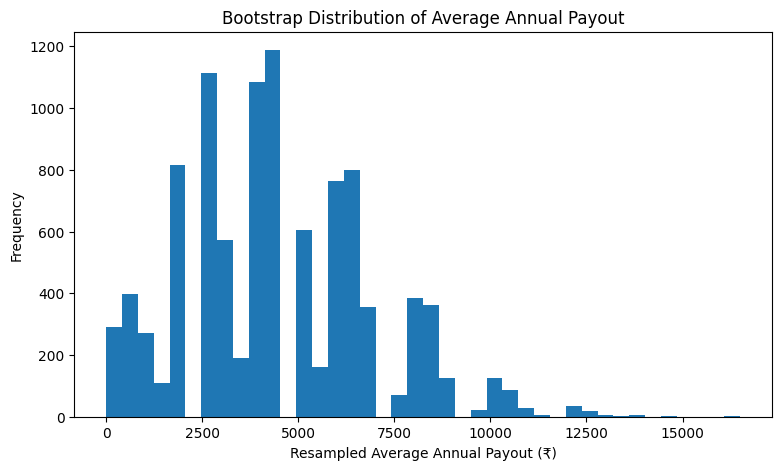

In [11]:


payouts = monsoon_rainfall["payout_rs"].to_numpy()

np.random.seed(42)

bootstrap_means = [
    np.random.choice(payouts, size=len(payouts), replace=True).mean()
    for _ in range(10000)
]

lower = np.percentile(bootstrap_means, 2.5)
upper = np.percentile(bootstrap_means, 97.5)

print(f"Historical average payout: ₹{payouts.mean():,.2f}")
print(f"Bootstrap 95% interval: ₹{lower:,.2f} to ₹{upper:,.2f}")

plt.figure(figsize=(9, 5))
plt.hist(bootstrap_means, bins=40)
plt.xlabel("Resampled Average Annual Payout (₹)")
plt.ylabel("Frequency")
plt.title("Bootstrap Distribution of Average Annual Payout")
plt.show()

In [12]:
triggers = [700, 800, 900, 1000]
results = []

for trigger in triggers:
    payouts = (
        (trigger - monsoon_rainfall["monsoon_rainfall_mm"])
        .clip(lower=0) * PAYOUT_PER_MM
    ).clip(upper=MAX_PAYOUT)

    results.append({
        "trigger_mm": trigger,
        "payout_frequency_pct": (payouts > 0).mean() * 100,
        "average_annual_payout_rs": payouts.mean(),
        "maximum_payout_rs": payouts.max()
    })

trigger_analysis = pd.DataFrame(results)
print(trigger_analysis.round(2).to_string(index=False))

 trigger_mm  payout_frequency_pct  average_annual_payout_rs  maximum_payout_rs
        700                  20.0                    2411.0            13510.0
        800                  30.0                    4500.0            20000.0
        900                  30.0                    5500.0            20000.0
       1000                  70.0                    7948.0            20000.0


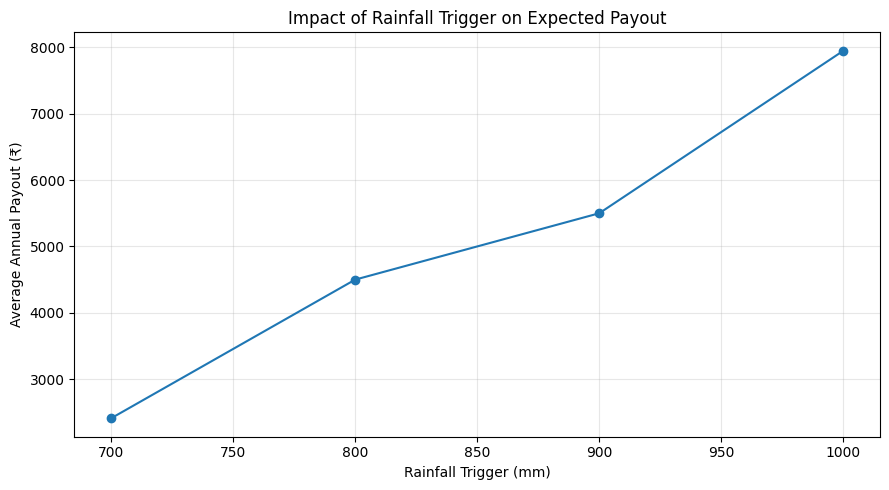

In [13]:
plt.figure(figsize=(9, 5))

plt.plot(
    trigger_analysis["trigger_mm"],
    trigger_analysis["average_annual_payout_rs"],
    marker="o"
)

plt.xlabel("Rainfall Trigger (mm)")
plt.ylabel("Average Annual Payout (₹)")
plt.title("Impact of Rainfall Trigger on Expected Payout")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [14]:
TRIGGER_MM = 800

monsoon_rainfall["shortfall_mm"] = (
    TRIGGER_MM - monsoon_rainfall["monsoon_rainfall_mm"]
).clip(lower=0)

monsoon_rainfall["trigger_breached"] = (
    monsoon_rainfall["monsoon_rainfall_mm"] < TRIGGER_MM
)

print(
    monsoon_rainfall[
        ["year", "monsoon_rainfall_mm",
         "shortfall_mm", "trigger_breached", "payout_rs"]
    ].to_string(index=False)
)

 year  monsoon_rainfall_mm  shortfall_mm  trigger_breached  payout_rs
 2015                564.9         235.1              True    20000.0
 2016                594.0         206.0              True    20000.0
 2017               1561.5           0.0             False        0.0
 2018                750.0          50.0              True     5000.0
 2019               1177.4           0.0             False        0.0
 2020                984.8           0.0             False        0.0
 2021                935.5           0.0             False        0.0
 2022                949.5           0.0             False        0.0
 2023                935.4           0.0             False        0.0
 2024               1260.4           0.0             False        0.0


In [15]:
# Select seasons with positive payouts
claim_years = monsoon_rainfall[
    monsoon_rainfall["payout_rs"] > 0
].copy()

print("Number of claim seasons:", len(claim_years))

print("\nPayout severity statistics:")
print(claim_years["payout_rs"].describe())

print("\nAverage payout when a claim occurs: ₹",
      round(claim_years["payout_rs"].mean(), 2))

print("\nTotal payout across claim seasons: ₹",
      claim_years["payout_rs"].sum())

Number of claim seasons: 3

Payout severity statistics:
count        3.000000
mean     15000.000000
std       8660.254038
min       5000.000000
25%      12500.000000
50%      20000.000000
75%      20000.000000
max      20000.000000
Name: payout_rs, dtype: float64

Average payout when a claim occurs: ₹ 15000.0

Total payout across claim seasons: ₹ 45000.0


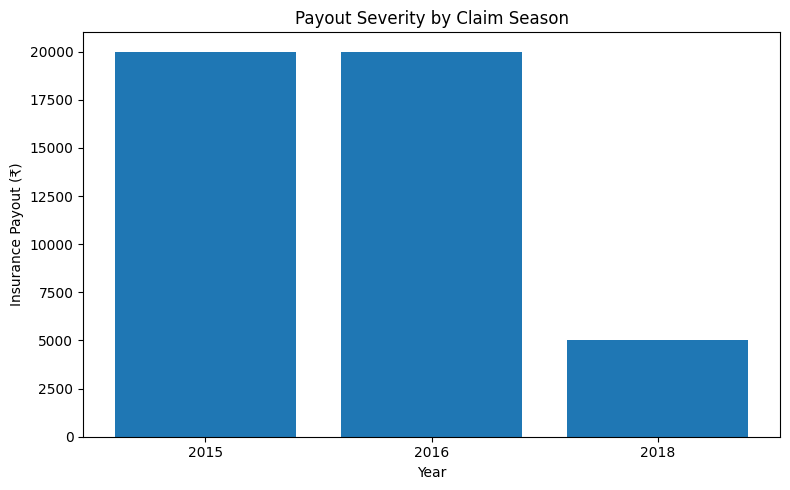

In [16]:
plt.figure(figsize=(8, 5))

plt.bar(
    claim_years["year"].astype(str),
    claim_years["payout_rs"]
)

plt.xlabel("Year")
plt.ylabel("Insurance Payout (₹)")
plt.title("Payout Severity by Claim Season")
plt.tight_layout()
plt.show()

In [17]:
# Validate the insurance contract
assert (monsoon_rainfall["payout_rs"] >= 0).all()
assert (monsoon_rainfall["payout_rs"] <= MAX_PAYOUT).all()

expected_payouts = (
    (TRIGGER_MM - monsoon_rainfall["monsoon_rainfall_mm"])
    .clip(lower=0) * PAYOUT_PER_MM
).clip(upper=MAX_PAYOUT)

assert np.allclose(
    monsoon_rainfall["payout_rs"],
    expected_payouts
)

print("All validation checks passed!")
print("No negative payouts.")
print("No payouts exceed the maximum limit.")
print("Payouts match the contract rules.")

All validation checks passed!
No negative payouts.
No payouts exceed the maximum limit.
Payouts match the contract rules.


In [18]:
train = monsoon_rainfall[
    monsoon_rainfall["year"] <= 2021
].copy()

test = monsoon_rainfall[
    monsoon_rainfall["year"] >= 2022
].copy()

print("Calibration period:", train["year"].min(), "-", train["year"].max())
print("Test period:", test["year"].min(), "-", test["year"].max())

print("\nCalibration years:", len(train))
print("Test years:", len(test))

print("\nCalibration average payout: ₹",
      round(train["payout_rs"].mean(), 2))

print("Test average payout: ₹",
      round(test["payout_rs"].mean(), 2))

Calibration period: 2015 - 2021
Test period: 2022 - 2024

Calibration years: 7
Test years: 3

Calibration average payout: ₹ 6428.57
Test average payout: ₹ 0.0


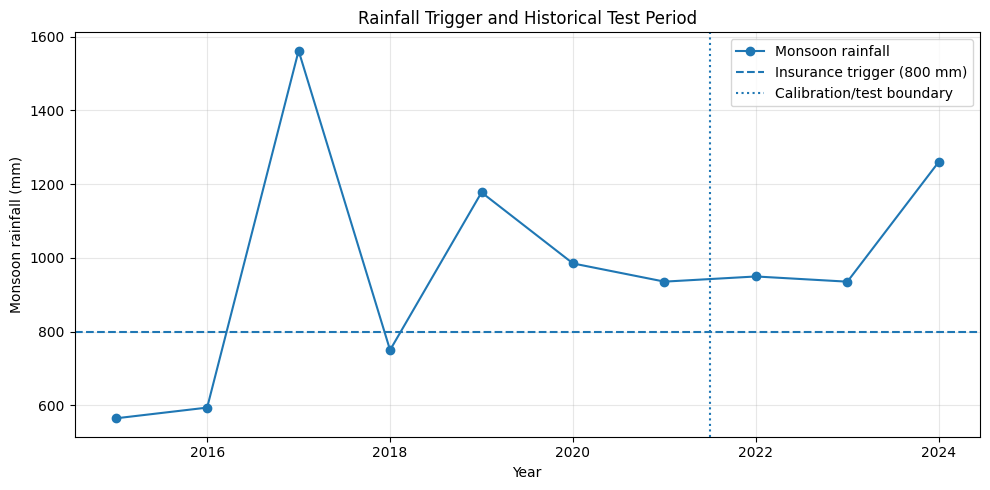

In [19]:
plt.figure(figsize=(10, 5))

plt.plot(
    monsoon_rainfall["year"],
    monsoon_rainfall["monsoon_rainfall_mm"],
    marker="o",
    label="Monsoon rainfall"
)

plt.axhline(
    y=TRIGGER_MM,
    linestyle="--",
    label="Insurance trigger (800 mm)"
)

plt.axvline(
    x=2021.5,
    linestyle=":",
    label="Calibration/test boundary"
)

plt.xlabel("Year")
plt.ylabel("Monsoon rainfall (mm)")
plt.title("Rainfall Trigger and Historical Test Period")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [20]:
def evaluate_period(df):
    return pd.Series({
        "years": len(df),
        "trigger_breaches": (
            df["monsoon_rainfall_mm"] < TRIGGER_MM
        ).sum(),
        "breach_rate_pct": (
            df["monsoon_rainfall_mm"] < TRIGGER_MM
        ).mean() * 100,
        "total_payout_rs": df["payout_rs"].sum(),
        "average_payout_rs": df["payout_rs"].mean()
    })

comparison = pd.DataFrame({
    "Calibration": evaluate_period(train),
    "Test": evaluate_period(test)
}).T

print(comparison.round(2))

             years  trigger_breaches  breach_rate_pct  total_payout_rs  \
Calibration    7.0               3.0            42.86          45000.0   
Test           3.0               0.0             0.00              0.0   

             average_payout_rs  
Calibration            6428.57  
Test                      0.00  


In [21]:
# Save the main analysis tables
monsoon_rainfall.to_csv(
    "monsoon_rainfall_payouts.csv", index=False
)

trigger_analysis.to_csv(
    "trigger_sensitivity.csv", index=False
)

comparison.to_csv(
    "calibration_test_comparison.csv"
)

print("Project outputs saved successfully!")




Project outputs saved successfully!


In [22]:
summary = {
    "location": "Ahmedabad",
    "period": "2015–2024",
    "monsoon_months": "June–September",
    "rainfall_trigger_mm": TRIGGER_MM,
    "payout_per_mm_rs": PAYOUT_PER_MM,
    "maximum_payout_rs": MAX_PAYOUT,
    "historical_average_payout_rs": round(
        monsoon_rainfall["payout_rs"].mean(), 2
    ),
    "historical_payout_frequency_pct": round(
        (monsoon_rainfall["payout_rs"] > 0).mean() * 100, 2
    ),
    "calibration_average_payout_rs": round(
        train["payout_rs"].mean(), 2
    ),
    "test_average_payout_rs": round(
        test["payout_rs"].mean(), 2
    )
}

for key, value in summary.items():
    print(f"{key}: {value}")

location: Ahmedabad
period: 2015–2024
monsoon_months: June–September
rainfall_trigger_mm: 800
payout_per_mm_rs: 100
maximum_payout_rs: 20000
historical_average_payout_rs: 4500.0
historical_payout_frequency_pct: 30.0
calibration_average_payout_rs: 6428.57
test_average_payout_rs: 0.0
